In [22]:
print("=== PROJECT SUMMARY ===")
print(f"Total Leads Analysed: {len(df)}")
print(f"Overall Conversion Rate: {round(df['converted'].mean() * 100, 2)}%")
print(f"\nLead Segments:")
print(df['segment'].value_counts())
print(f"\nTop 3 Conversion Drivers:")
print(feature_importance[['feature', 'importance']].head(3).to_string(index=False))
print(f"\nModel ROC-AUC Score: {round(roc_score * 100, 2)}%")
print("\nRanked leads list saved to data/ranked_leads.csv")
print("Model saved to models/lead_scoring_model.pkl")

=== PROJECT SUMMARY ===
Total Leads Analysed: 5000
Overall Conversion Rate: 14.54%

Lead Segments:
segment
Low Intent       4250
High Intent       564
Medium Intent     186
Name: count, dtype: int64

Top 3 Conversion Drivers:
      feature  importance
 time_on_site    0.082915
response_time    0.079638
          age    0.069899

Model ROC-AUC Score: 50.57%

Ranked leads list saved to data/ranked_leads.csv
Model saved to models/lead_scoring_model.pkl


In [21]:
import joblib

# Save the trained model
joblib.dump(rf_smote, '../models/lead_scoring_model.pkl')
joblib.dump(X.columns.tolist(), '../models/feature_columns.pkl')
print("Model saved successfully!")

Model saved successfully!


In [20]:
from sklearn.metrics import roc_auc_score
import numpy as np

rf_probs_test = rf_smote.predict_proba(X_test)[:, 1]
roc_score = roc_auc_score(y_test, rf_probs_test)
print("=== Final Model Evaluation ===")
print(f"ROC-AUC Score: {round(roc_score * 100, 2)}%") 

=== Final Model Evaluation ===
ROC-AUC Score: 50.57%


In [19]:
# Create ranked lead list by conversion score
ranked_leads = df[['lead_id', 'name', 'age', 'income', 'location', 
                    'source', 'interest_type', 'conversion_score', 
                    'segment']].sort_values('conversion_score', ascending=False)

print("=== Top 20 Highest Priority Leads ===")
print(ranked_leads.head(20))

# Save to CSV
ranked_leads.to_csv('../data/ranked_leads.csv', index=False)
print("\nRanked leads saved to data/ranked_leads.csv")

=== Top 20 Highest Priority Leads ===
         lead_id       name  age  income     location          source  \
1374  LEAD_01375  Lead_1375   33   50000       Ottawa      google_ads   
1308  LEAD_01309  Lead_1309   37   80000     Hamilton    facebook_ads   
2473  LEAD_02474  Lead_2474   54   65000      Toronto    facebook_ads   
710   LEAD_00711   Lead_711   56   50000     Brampton      google_ads   
4983  LEAD_04984  Lead_4984   59  150000  Mississauga    facebook_ads   
2310  LEAD_02311  Lead_2311   45  200000     Brampton  organic_search   
10    LEAD_00011    Lead_11   23   50000       Ottawa      google_ads   
101   LEAD_00102   Lead_102   50   80000     Brampton      google_ads   
1234  LEAD_01235  Lead_1235   51   65000      Toronto        referral   
3262  LEAD_03263  Lead_3263   41  100000     Brampton      google_ads   
4026  LEAD_04027  Lead_4027   40   80000     Brampton    facebook_ads   
995   LEAD_00996   Lead_996   27   80000  Mississauga      google_ads   
2012  LEAD_02

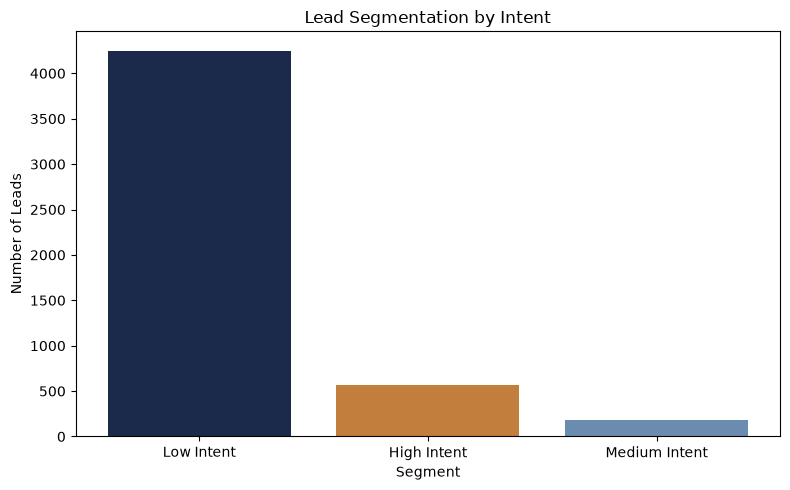

In [18]:
# Plot segment distribution
segment_counts = df['segment'].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(segment_counts.index, segment_counts.values, 
        color=['#1B2A4A', '#C17E3C', '#6B8CAE'])
plt.title('Lead Segmentation by Intent')
plt.xlabel('Segment')
plt.ylabel('Number of Leads')
plt.tight_layout()
plt.show()

In [17]:
# Get conversion probabilities for all leads
df['conversion_score'] = rf_smote.predict_proba(X)[:, 1]

# Segment leads into High, Medium, Low intent
def segment_lead(score):
    if score >= 0.6:
        return 'High Intent'
    elif score >= 0.3:
        return 'Medium Intent'
    else:
        return 'Low Intent'

df['segment'] = df['conversion_score'].apply(segment_lead)

# Show segment counts
print("=== Lead Segments ===")
print(df['segment'].value_counts())
print("\nPercentage breakdown:")
print(df['segment'].value_counts(normalize=True) * 100)

=== Lead Segments ===
segment
Low Intent       4250
High Intent       564
Medium Intent     186
Name: count, dtype: int64

Percentage breakdown:
segment
Low Intent       85.00
High Intent      11.28
Medium Intent     3.72
Name: proportion, dtype: float64


=== Top 10 Conversion Drivers ===
                      feature  importance
3                time_on_site    0.082915
10              response_time    0.079638
0                         age    0.069899
25  interest_type_family_home    0.050568
27   interest_type_investment    0.046958
26   interest_type_first_time    0.046509
1                      income    0.045783
4              property_views    0.041347
15           location_Toronto    0.037278
29     interest_type_off_plan    0.033439


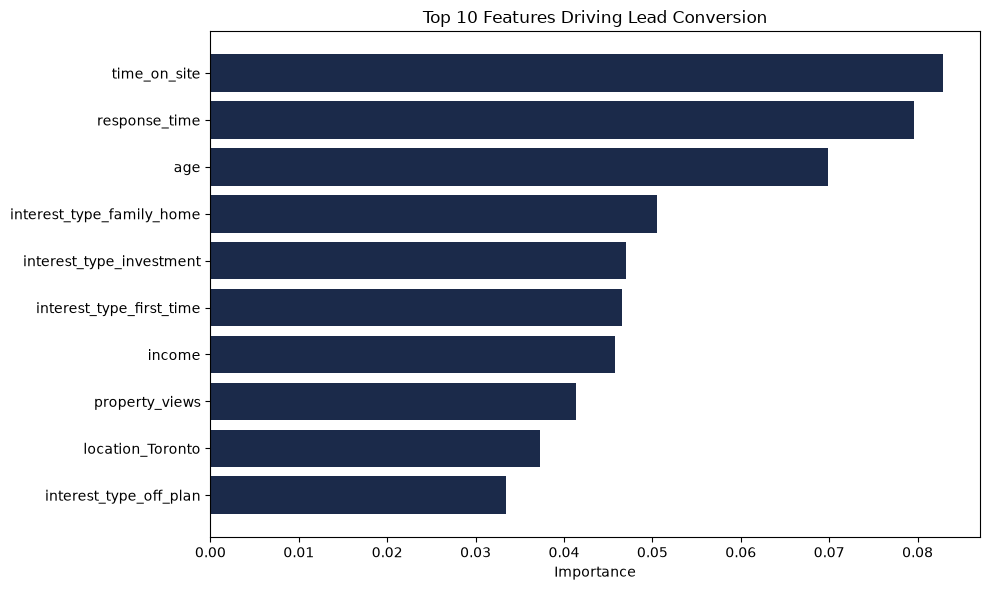

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_smote.feature_importances_
}).sort_values('importance', ascending=False).head(10)

print("=== Top 10 Conversion Drivers ===")
print(feature_importance)

# Plot
plt.figure(figsize=(10, 6))
plt.barh(feature_importance['feature'], feature_importance['importance'], color='#1B2A4A')
plt.xlabel('Importance')
plt.title('Top 10 Features Driving Lead Conversion')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [15]:
# Get probabilities instead of hard predictions
rf_probs = rf_smote.predict_proba(X_test)[:, 1]

# Lower the threshold to 0.3
threshold = 0.3
rf_threshold_predictions = (rf_probs >= threshold).astype(int)

print("=== Random Forest + SMOTE + Lower Threshold ===")
print("Accuracy:", round(accuracy_score(y_test, rf_threshold_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, rf_threshold_predictions) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, rf_threshold_predictions) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, rf_threshold_predictions) * 100, 2), "%")

=== Random Forest + SMOTE + Lower Threshold ===
Accuracy: 71.2 %
Precision: 15.76 %
Recall: 17.9 %
F1 Score: 16.76 %


In [14]:
from imblearn.over_sampling import SMOTE

# Balance the training data
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())
print("\nAfter SMOTE:")
print(y_train_balanced.value_counts())

# Retrain Random Forest on balanced data
rf_smote = RandomForestClassifier(n_estimators=100, random_state=42)
rf_smote.fit(X_train_balanced, y_train_balanced)

rf_smote_predictions = rf_smote.predict(X_test)

print("\n=== Random Forest + SMOTE Results ===")
print("Accuracy:", round(accuracy_score(y_test, rf_smote_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, rf_smote_predictions) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, rf_smote_predictions) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, rf_smote_predictions) * 100, 2), "%")

Before SMOTE:
converted
0    3435
1     565
Name: count, dtype: int64

After SMOTE:
converted
1    3435
0    3435
Name: count, dtype: int64

=== Random Forest + SMOTE Results ===
Accuracy: 82.9 %
Precision: 15.38 %
Recall: 1.23 %
F1 Score: 2.29 %


In [13]:
# Retrain Random Forest with class balancing
rf_model_balanced = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced',
    random_state=42
)
rf_model_balanced.fit(X_train, y_train)

rf_balanced_predictions = rf_model_balanced.predict(X_test)

print("=== Balanced Random Forest Results ===")
print("Accuracy:", round(accuracy_score(y_test, rf_balanced_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, rf_balanced_predictions) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, rf_balanced_predictions) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, rf_balanced_predictions) * 100, 2), "%")

=== Balanced Random Forest Results ===
Accuracy: 82.4 %
Precision: 6.25 %
Recall: 0.62 %
F1 Score: 1.12 %


In [12]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate
print("=== Random Forest Results ===")
print("Accuracy:", round(accuracy_score(y_test, rf_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, rf_predictions) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, rf_predictions) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, rf_predictions) * 100, 2), "%")

=== Random Forest Results ===
Accuracy: 83.7 %
Precision: 0.0 %
Recall: 0.0 %
F1 Score: 0.0 %


In [11]:
from sklearn.tree import DecisionTreeClassifier

# Train Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test)

# Evaluate
print("=== Decision Tree Results ===")
print("Accuracy:", round(accuracy_score(y_test, dt_predictions) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, dt_predictions) * 100, 2), "%")
print("Recall:", round(recall_score(y_test, dt_predictions) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, dt_predictions) * 100, 2), "%")

=== Decision Tree Results ===
Accuracy: 73.0 %
Precision: 20.97 %
Recall: 24.07 %
F1 Score: 22.41 %


In [10]:
from sklearn.model_selection import train_test_split

# Separate features (X) from target (y)
X = df_model.drop(columns=['converted'])
y = df_model['converted']

# Split 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (4000, 30)
Testing set size: (1000, 30)


In [9]:
# Drop columns we don't need for the model
df_model = df.drop(columns=['lead_id', 'name', 'lead_date', 'conversion_probability'])

# Convert categorical columns to numbers
df_model = pd.get_dummies(df_model, columns=['location', 'source', 'interest_type'])

print("Model dataset shape:", df_model.shape)
df_model.head()

Model dataset shape: (5000, 31)


,age,income,converted,website_visits,time_on_site,property_views,brochure_downloaded,whatsapp_clicks,agent_calls,emails_sent,...,source_linkedin_ads,source_listing_portal,source_organic_search,source_referral,source_tiktok_ads,interest_type_family_home,interest_type_first_time,interest_type_investment,interest_type_luxury,interest_type_off_plan
0,39,65000,0,1,94.5,2,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
1,66,65000,0,1,55.9,1,0,0,0,0,...,False,True,False,False,False,True,False,False,False,False
2,54,125000,0,1,36.2,2,0,0,2,3,...,False,False,True,False,False,True,False,False,False,False
3,49,65000,0,5,105.4,6,0,0,0,0,...,False,False,False,False,False,False,True,False,False,False
4,29,125000,1,2,160.7,3,0,3,1,1,...,False,False,False,False,False,False,False,True,False,False


In [8]:
print("Conversion Rate:")
print(df['converted'].value_counts())
print("\nPercentage:")
print(df['converted'].value_counts(normalize=True) * 100)

Conversion Rate:
converted
0    4273
1     727
Name: count, dtype: int64

Percentage:
converted
0    85.46
1    14.54
Name: proportion, dtype: float64


In [7]:
# Merge leads with engagement and interactions on lead_id
df = leads.merge(engagement, on='lead_id').merge(interactions, on='lead_id')

print("Merged dataset shape:", df.shape)
df.head()

Merged dataset shape: (5000, 19)


,lead_id,name,age,income,location,source,interest_type,lead_date,conversion_probability,converted,website_visits,time_on_site,property_views,brochure_downloaded,whatsapp_clicks,agent_calls,emails_sent,meetings_booked,response_time
0,LEAD_00001,Lead_1,39,65000,Mississauga,instagram_ads,first_time,2026-05-31 16:58:06.023597,0.090358,0,1,94.5,2,0,0,0,0,0,141.6
1,LEAD_00002,Lead_2,66,65000,Toronto,listing_portal,family_home,2026-05-31 16:58:06.023597,0.112671,0,1,55.9,1,0,0,0,0,0,67.1
2,LEAD_00003,Lead_3,54,125000,Toronto,organic_search,family_home,2026-05-31 16:58:06.023597,0.165639,0,1,36.2,2,0,0,2,3,0,57.6
3,LEAD_00004,Lead_4,49,65000,Brampton,google_ads,first_time,2026-05-31 16:58:06.023597,0.085632,0,5,105.4,6,0,0,0,0,0,331.8
4,LEAD_00005,Lead_5,29,125000,Mississauga,facebook_ads,investment,2026-05-31 16:58:06.023597,0.166770,1,2,160.7,3,0,3,1,1,0,53.8


In [6]:
print("Missing values in leads:")
print(leads.isnull().sum())
print("\nMissing values in engagement:")
print(engagement.isnull().sum())
print("\nMissing values in interactions:")
print(interactions.isnull().sum())

Missing values in leads:
lead_id                   0
name                      0
age                       0
income                    0
location                  0
source                    0
interest_type             0
lead_date                 0
conversion_probability    0
converted                 0
dtype: int64

Missing values in engagement:
lead_id                0
website_visits         0
time_on_site           0
property_views         0
brochure_downloaded    0
whatsapp_clicks        0
dtype: int64

Missing values in interactions:
lead_id            0
agent_calls        0
emails_sent        0
meetings_booked    0
response_time      0
dtype: int64


In [3]:
print("Leads shape:", leads.shape)
print("Engagement shape:", engagement.shape)
print("Interactions shape:", interactions.shape)
print("Properties shape:", properties.shape)
leads.head()

Leads shape: (5000, 10)
Engagement shape: (5000, 6)
Interactions shape: (5000, 5)
Properties shape: (8, 5)


,lead_id,name,age,income,location,source,interest_type,lead_date,conversion_probability,converted
0,LEAD_00001,Lead_1,39,65000,Mississauga,instagram_ads,first_time,2026-05-31 16:58:06.023597,0.090358,0
1,LEAD_00002,Lead_2,66,65000,Toronto,listing_portal,family_home,2026-05-31 16:58:06.023597,0.112671,0
2,LEAD_00003,Lead_3,54,125000,Toronto,organic_search,family_home,2026-05-31 16:58:06.023597,0.165639,0
3,LEAD_00004,Lead_4,49,65000,Brampton,google_ads,first_time,2026-05-31 16:58:06.023597,0.085632,0
4,LEAD_00005,Lead_5,29,125000,Mississauga,facebook_ads,investment,2026-05-31 16:58:06.023597,0.166770,1


In [2]:
leads = pd.read_csv('../data/leads.csv')
engagement = pd.read_csv('../data/engagement.csv')
interactions = pd.read_csv('../data/interactions.csv')
properties = pd.read_csv('../data/properties.csv') 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


Matplotlib is building the font cache; this may take a moment.
